
# Gradient Boosting and Explainability

## 1. Introduction

This notebook presents the implementation and evaluation of the Gradient Boosting model for the Credit Card Default Prediction project.

The main objectives of this section are:

- To develop a Gradient Boosting classification model.
- To improve model performance through hyperparameter tuning.
- To evaluate the model using cross-validation metrics.
- To identify important features that influence model predictions.
- To provide recommendations based on the model interpretation.

The shared preprocessing pipeline developed by M2 is used to ensure consistency across all machine learning models.

In [2]:

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Locate the results folder
if Path("results").exists():
    results_dir = Path("results")
elif Path("../results").exists():
    results_dir = Path("../results")
else:
    raise FileNotFoundError("Cannot find the results folder.")

print("Results folder:", results_dir.resolve())
print("Libraries imported successfully.")

Results folder: /Users/chia/ML-Group8-Project/results
Libraries imported successfully.



## 2. Load Gradient Boosting Results

The Gradient Boosting model results were saved in JSON and CSV files.

These files contain the results from baseline evaluation, hyperparameter tuning, supporting evaluation metrics and feature importance analysis.

In [3]:

# Load the saved Gradient Boosting results
with open(results_dir / "gb_cv.json", "r", encoding="utf-8") as file:
    gb_results = json.load(file)

print("Gradient Boosting results loaded successfully.")

# Display the saved results
print("\nSaved Model Results:")
print(json.dumps(gb_results, indent=4))

Gradient Boosting results loaded successfully.

Saved Model Results:
{
    "model": "gb",
    "cv_folds": 3,
    "random_state": 42,
    "scoring": "f1",
    "baseline_f1_mean": 0.47569587671142055,
    "baseline_f1_std": 0.004842988749541104,
    "tuned_f1_mean": 0.47906127660781933,
    "tuned_f1_std": 0.0073701852999119855,
    "best_params": {
        "model__subsample": 0.8,
        "model__n_estimators": 200,
        "model__min_samples_split": 10,
        "model__min_samples_leaf": 2,
        "model__max_depth": 3,
        "model__learning_rate": 0.05
    },
    "search_method": "RandomizedSearchCV",
    "search_space": {
        "model__n_estimators": [
            100,
            150,
            200
        ],
        "model__learning_rate": [
            0.03,
            0.05,
            0.1
        ],
        "model__max_depth": [
            2,
            3
        ],
        "model__min_samples_split": [
            2,
            5,
            10
        ],
        


## 3. Baseline Model and Hyperparameter Tuning

The baseline Gradient Boosting model was evaluated using 3-fold Stratified Cross-Validation.

RandomizedSearchCV was then applied to search for better hyperparameter combinations.

The F1-score was selected as the main tuning metric because the dataset contains an imbalanced target variable.

In [4]:

# Baseline and tuned model performance
baseline_f1 = 0.4757
tuned_f1 = 0.4791

comparison = pd.DataFrame({
    "Model": ["Baseline Gradient Boosting", "Tuned Gradient Boosting"],
    "Mean Cross-Validation F1": [baseline_f1, tuned_f1]
})

display(comparison)

improvement = tuned_f1 - baseline_f1

print(f"F1-score improvement: {improvement:.4f}")
print(f"Percentage-point improvement: {improvement * 100:.2f}%")

,Model,Mean Cross-Validation F1
0,Baseline Gradient Boosting,0.4757
1,Tuned Gradient Boosting,0.4791


F1-score improvement: 0.0034
Percentage-point improvement: 0.34%


In [5]:

# Display the best hyperparameters
best_params = gb_results.get("best_params", {})

print("Best Hyperparameters:")
for parameter, value in best_params.items():
    print(f"{parameter}: {value}")

Best Hyperparameters:
model__subsample: 0.8
model__n_estimators: 200
model__min_samples_split: 10
model__min_samples_leaf: 2
model__max_depth: 3
model__learning_rate: 0.05



## 4. Model Evaluation

The tuned Gradient Boosting model was evaluated using 3-fold cross-validation on the training dataset.

The following metrics were used:

- **F1-score:** Measures the balance between precision and recall.
- **Precision:** Measures how many predicted defaults were actually defaults.
- **Recall:** Measures how many actual defaults were correctly identified.
- **ROC-AUC:** Measures the model's ability to distinguish between the two classes.
- **PR-AUC:** Evaluates the precision-recall trade-off, which is useful for imbalanced datasets.

The final test dataset was reserved for the common evaluation process conducted by M3.

In [6]:

# Cross-validation evaluation results
evaluation_results = pd.DataFrame({
    "Metric": ["F1-score", "Precision", "Recall", "ROC-AUC", "PR-AUC"],
    "Training Mean": [0.5008, 0.7116, 0.3864, 0.8142, 0.6141],
    "Validation Mean": [0.4791, 0.6808, 0.3696, 0.7822, 0.5571]
})

display(evaluation_results)

print("F1-score Train-Validation Gap: 0.0218")
print("Mean Model Fitting Time: 11.58 seconds")

,Metric,Training Mean,Validation Mean
0,F1-score,0.5008,0.4791
1,Precision,0.7116,0.6808
2,Recall,0.3864,0.3696
3,ROC-AUC,0.8142,0.7822
4,PR-AUC,0.6141,0.5571


F1-score Train-Validation Gap: 0.0218
Mean Model Fitting Time: 11.58 seconds



### 4.1 Evaluation Discussion

The tuned Gradient Boosting model achieved a validation F1-score of 0.4791.

The validation precision was 0.6808, indicating that approximately 68.08% of the customers predicted as potential defaulters were actual defaulters.

However, the recall was 0.3696, meaning that the model identified approximately 36.96% of actual defaulters.

The ROC-AUC score of 0.7822 indicates that the model has a reasonable ability to distinguish between default and non-default customers.

The training and validation F1-score gap was 0.0218. This indicates a relatively small performance difference between the training and validation results, although it does not completely rule out overfitting.

Overall, the model provides useful predictive information, but its relatively low recall indicates that further improvement may be needed to identify more potential defaulters.


## 5. Feature Importance Analysis

Feature importance analysis was conducted to understand which input variables contribute most to the Gradient Boosting model's predictions.

Two methods were used:

1. **Built-in Feature Importance:** Measures the contribution of transformed features within the trained Gradient Boosting model.
2. **Permutation Importance:** Measures how much the model's F1-score decreases when an original feature is randomly shuffled.

Using both methods provides additional insight into the features that the model relies on.

In [7]:

# Load built-in feature importance
feature_importance = pd.read_csv(
    results_dir / "gb_feature_importance.csv"
)

print("Top 15 Built-in Feature Importance:")
display(feature_importance.head(15))

Top 15 Built-in Feature Importance:


,feature,importance
0,categorical__PAY_0_2,0.438290
1,categorical__PAY_2_2,0.094933
2,categorical__PAY_3_2,0.049469
3,numeric__LIMIT_BAL,0.041310
4,numeric__PAY_AMT1,0.036251
5,categorical__PAY_5_2,0.031930
6,numeric__BILL_AMT1,0.031043
7,numeric__PAY_AMT2,0.029168
8,categorical__PAY_4_2,0.026919
9,categorical__PAY_0_3,0.026270


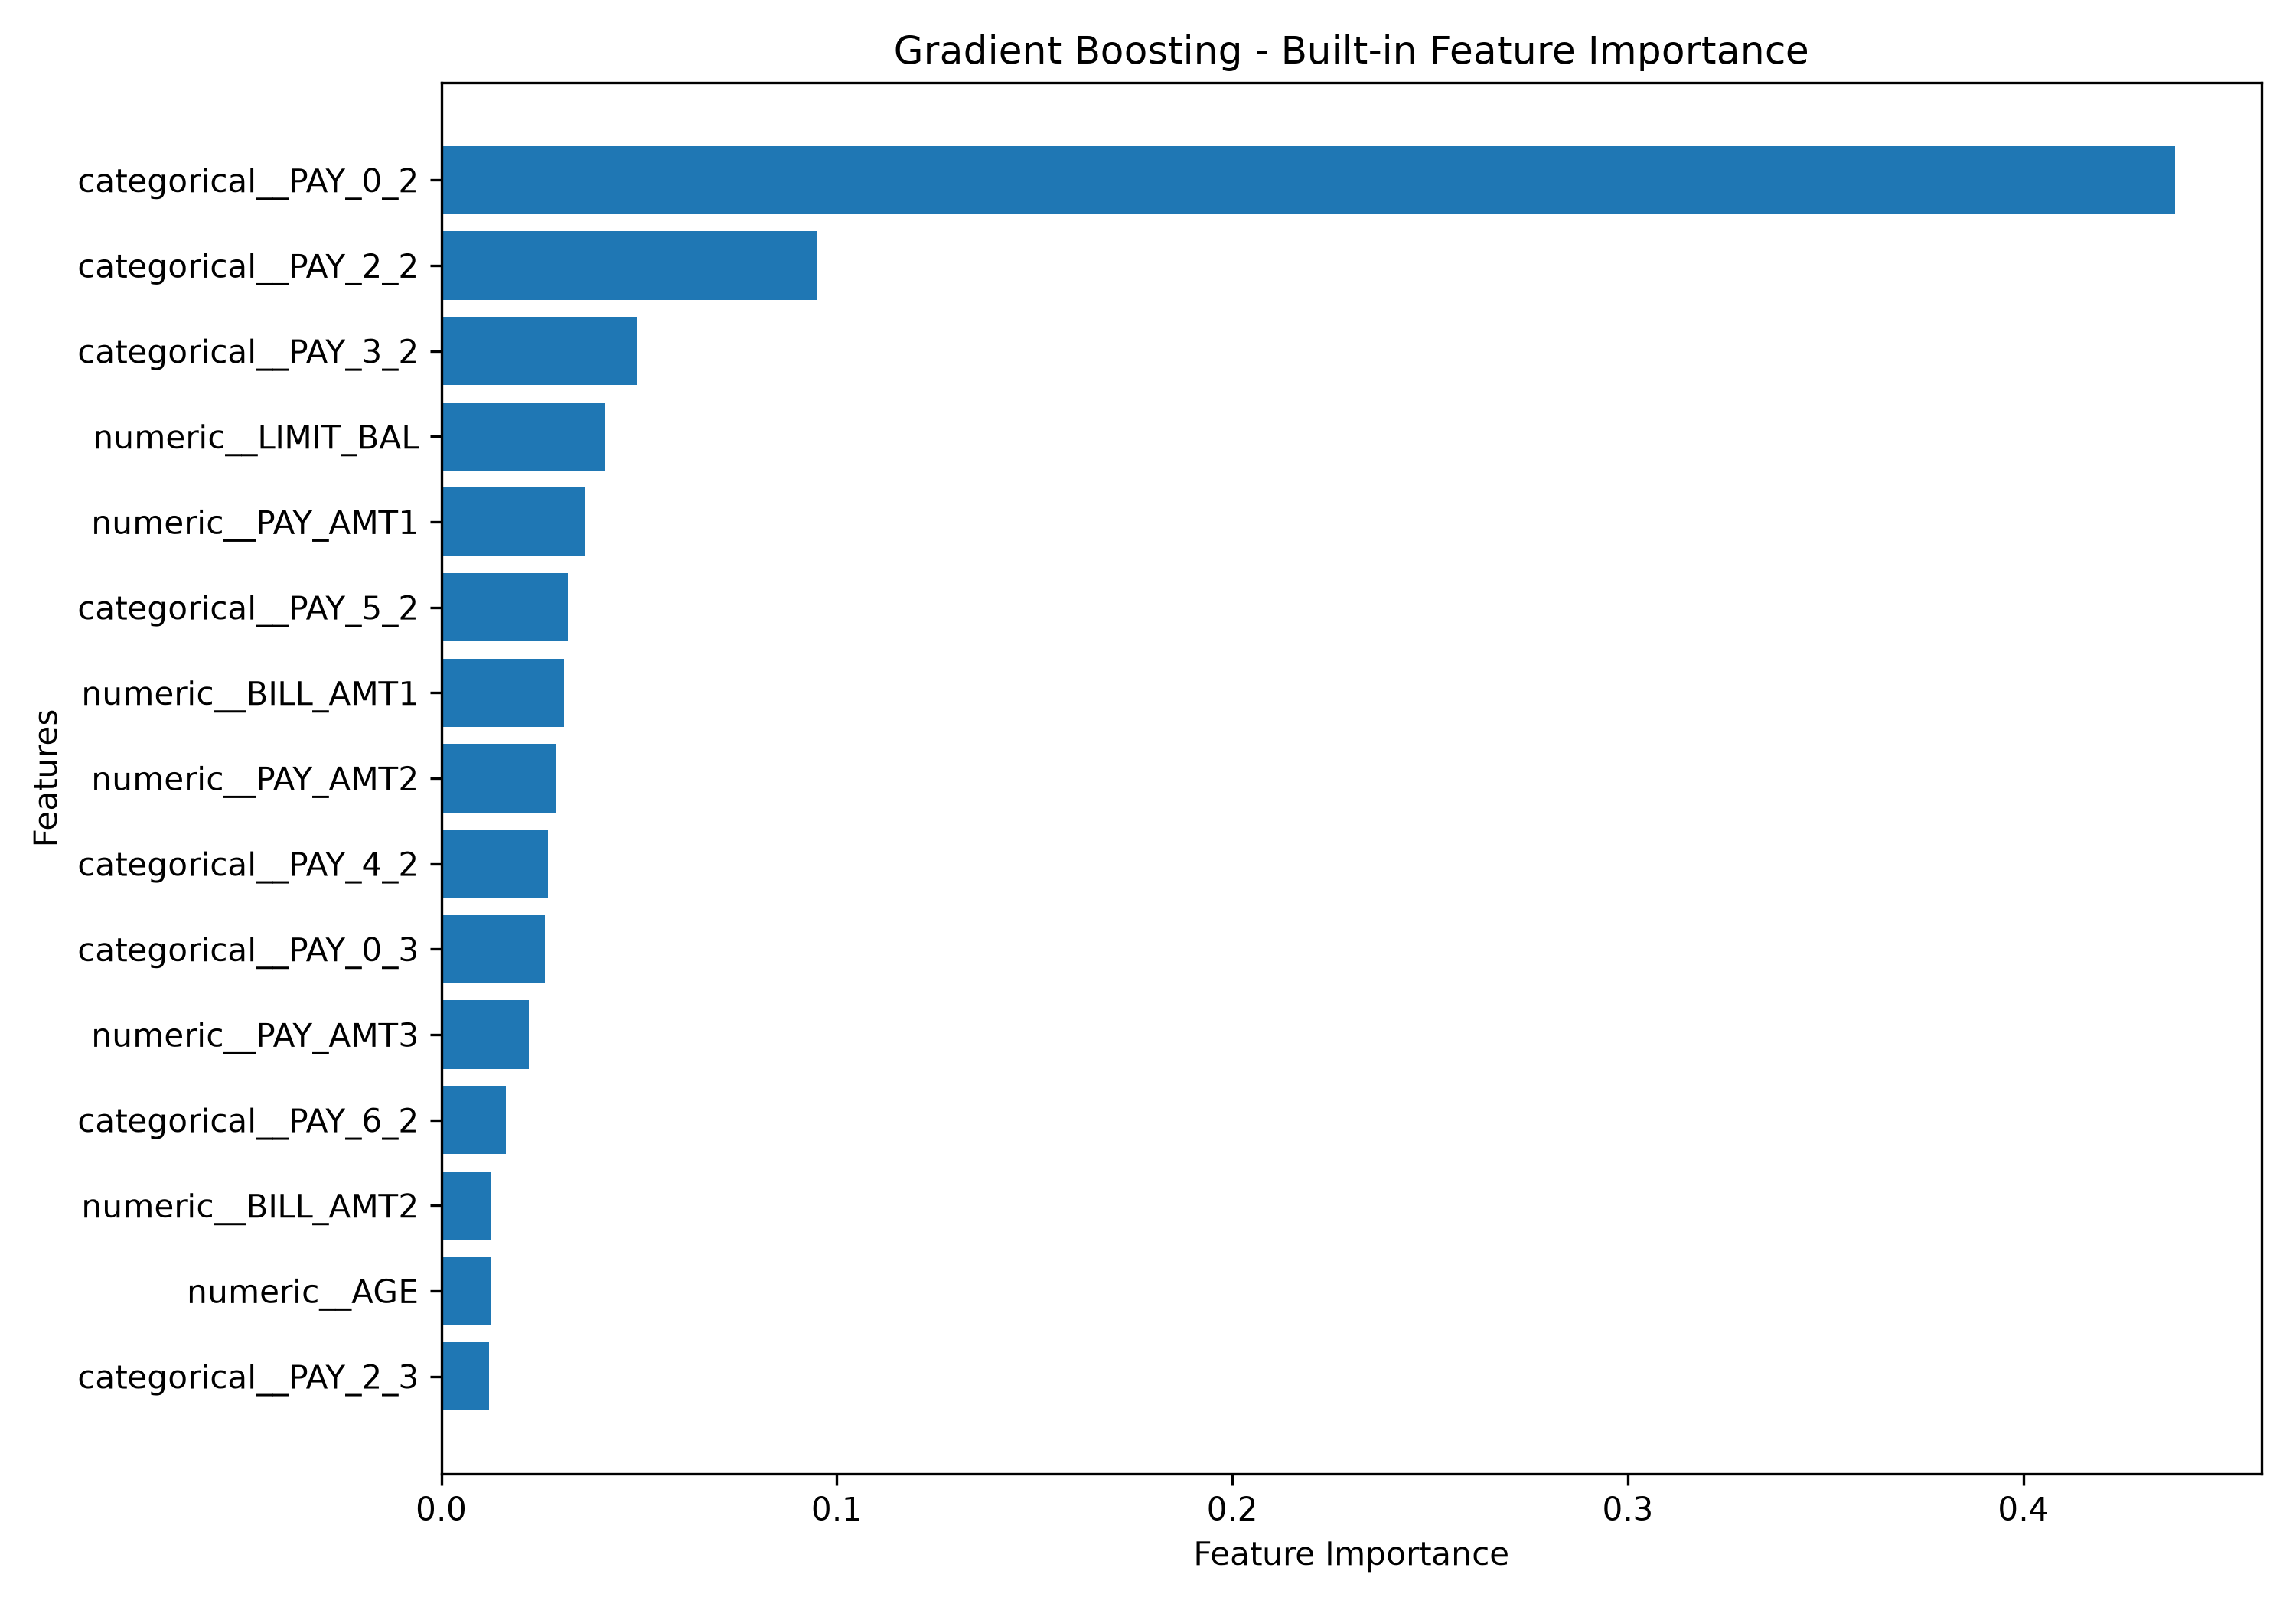

In [8]:

# Display built-in feature importance chart
feature_chart = results_dir / "gb_feature_importance.png"

display(Image(filename=str(feature_chart)))

In [9]:

# Load permutation importance
permutation_importance = pd.read_csv(
    results_dir / "gb_permutation_importance.csv"
)

print("Top 15 Permutation Importance:")
display(permutation_importance.head(15))

Top 15 Permutation Importance:


,feature,importance_mean,importance_std
0,PAY_0,0.204371,0.003545
1,PAY_2,0.028999,0.001240
2,PAY_3,0.016718,0.001276
3,LIMIT_BAL,0.015623,0.000717
4,PAY_AMT1,0.010583,0.001429
5,BILL_AMT1,0.010537,0.002725
6,PAY_5,0.009618,0.000637
7,PAY_AMT2,0.009484,0.001810
8,PAY_6,0.008730,0.001497
9,PAY_4,0.006010,0.000903


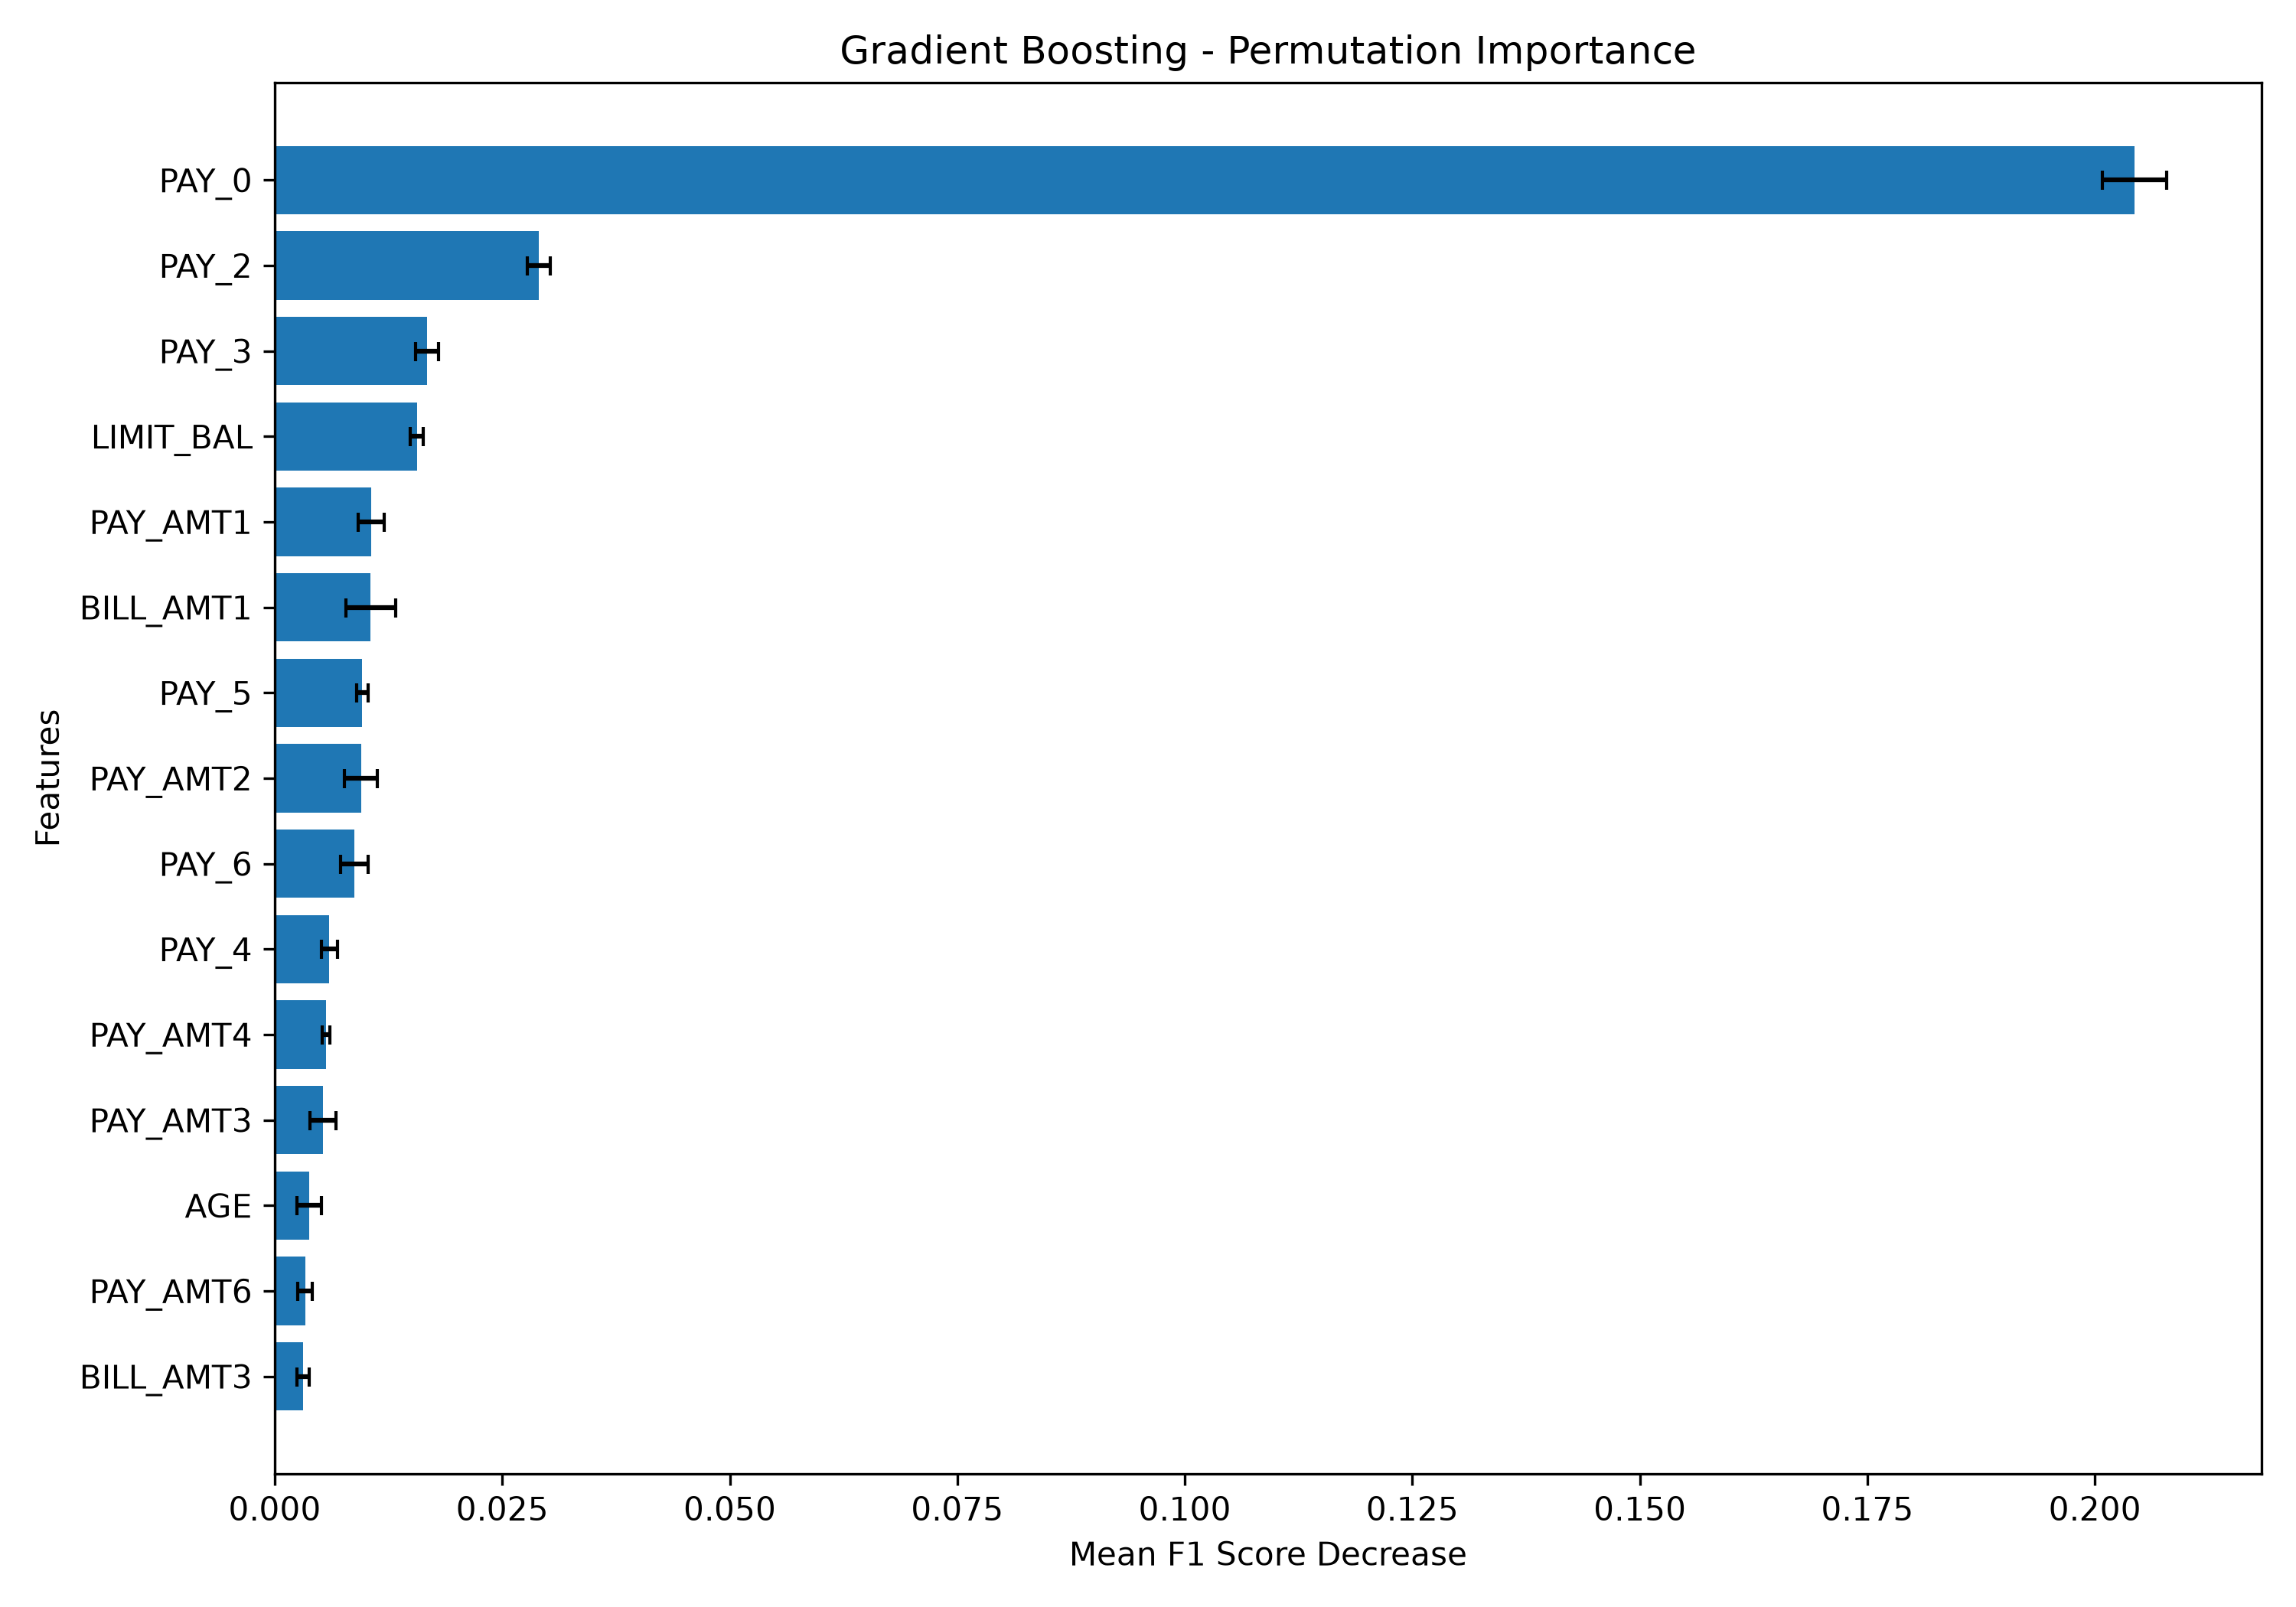

In [10]:

# Display permutation importance chart
permutation_chart = results_dir / "gb_permutation_importance.png"

display(Image(filename=str(permutation_chart)))


### 5.1 Feature Importance Discussion

Both feature importance methods identified PAY_0 as the most important feature.

PAY_0 represents the repayment status of the customer in the most recent month. Other important features include PAY_2, PAY_3 and LIMIT_BAL.

The built-in feature importance shows the importance of individual transformed features after one-hot encoding. In comparison, permutation importance evaluates the original input features by measuring their impact on the model's F1-score.

The similar ranking across both methods suggests that recent repayment status is an important factor used by the model when predicting credit card default.

However, feature importance indicates model reliance and association rather than a direct causal relationship.


## 6. Recommendations

Based on the model evaluation and feature importance results, the following recommendations are proposed:

1. Monitor Repayment Behaviour**

   Financial institutions should pay attention to customers' recent repayment status, especially PAY_0, PAY_2 and PAY_3.

2. Improve Early Risk Detection**

   The relatively low recall indicates that the model misses some actual defaulters. Further model improvement and threshold adjustment could help identify more potential default cases.

3. Provide Payment Reminders**

   Customers showing signs of delayed repayment could receive payment reminders and financial management information.

4. Combine Multiple Risk Factors**

   Credit limit, repayment history and payment amount should be considered together instead of relying on a single feature.

5. Consider Fairness and Privacy**

   Model predictions should be used as decision-support information rather than the only basis for financial decisions. Customer privacy and potential bias should also be considered.


## 7. Conclusion

In conclusion, the Gradient Boosting model was successfully implemented using the shared preprocessing pipeline.

Hyperparameter tuning improved the mean cross-validation F1-score from 0.4757 to 0.4791. The tuned model achieved a validation ROC-AUC of 0.7822 and PR-AUC of 0.5571.

Feature importance analysis identified recent repayment status, particularly PAY_0, as the most influential feature in the model.

Although the model demonstrates reasonable predictive performance, its recall remains relatively low. Further improvements may be required to identify more potential defaulters.

The results from this section can be used together with the other group models for the final model comparison and evaluation.